In [1]:
%cd "D:\Coding\projects\BatteryLifePrediction"

D:\Coding\projects\BatteryLifePrediction


In [2]:
"""⚙️ 参数区：换电芯时只需要改 CELL_FILE 这一行。"""
import pickle
from pathlib import Path

DATA_DIR = Path("data/raw/Tongji")
CELL_FILE = "Tongji1_CY45-05_1--1.pkl"  # ← 换电芯只改这里

I_TH_RATIO = 0.01  # 阶段切分阈值（0.01C），与 BatteryLife 口径一致
EOL_SOH = 0.80  # 寿命判据
SHOW_N_CYCLES = 3  # 老化对比图叠加的圈数（按实际圈数等间隔取）

PKL_PATH = DATA_DIR / CELL_FILE
if not PKL_PATH.exists():
    raise FileNotFoundError(f"找不到 {PKL_PATH}，请检查 CELL_FILE 或 DATA_DIR")

with PKL_PATH.open("rb") as f:
    cell = pickle.load(f)

cycles = sorted(cell["cycle_data"], key=lambda c: c["cycle_number"])
numbers = [c["cycle_number"] for c in cycles]
NOMINAL = cell["nominal_capacity_in_Ah"]
I_TH = I_TH_RATIO * NOMINAL

# 首/中/末：按实际圈数等间隔取样，而不是写死圈号
k = max(1, min(SHOW_N_CYCLES, len(numbers)))
if k == 1:
    SHOW_CYCLES = [numbers[0]]
else:
    idx = [round(i * (len(numbers) - 1) / (k - 1)) for i in range(k)]
    SHOW_CYCLES = sorted({numbers[i] for i in idx})

print(f"载入 {PKL_PATH.name}")
print(
    f"  圈数 {len(cycles)}（cycle {min(numbers)} ~ {max(numbers)}）| "
    f"额定 {NOMINAL} Ah | 叠加圈号 {SHOW_CYCLES}"
)


载入 Tongji1_CY45-05_1--1.pkl
  圈数 711（cycle 2 ~ 740）| 额定 3.5 Ah | 叠加圈号 [2, 371, 740]


In [3]:
"""材料信息、循环数、每轮采样点数统计（依赖"参数区"cell）。"""
import numpy as np

print(f"文件: {PKL_PATH.resolve()}")
print(f"cell_id: {cell['cell_id']}  |  form_factor: {cell['form_factor']}")

print("\n[材料]")
for label, key in [
    ("正极 cathode", "cathode_material"),
    ("负极 anode", "anode_material"),
    ("电解液 electrolyte", "electrolyte_material"),
]:
    value = cell.get(key)
    print(f"  {label:<20}: {value if value else 'None（数据中未提供）'}")

missing = sorted(set(range(min(numbers), max(numbers) + 1)) - set(numbers))
n_points = np.array([len(c["current_in_A"]) for c in cycles])

print("\n[循环与容量]")
print(f"  记录到的循环数    : {len(cycles)}")
print(
    f"  cycle_number 范围 : {min(numbers)} ~ {max(numbers)}"
    + (f"（缺失 {missing}）" if missing else "（无缺失）")
)
print(f"  额定容量          : {cell['nominal_capacity_in_Ah']} Ah")
print(
    f"  电压窗口          : {cell['min_voltage_limit_in_V']} ~ "
    f"{cell['max_voltage_limit_in_V']} V"
)

print("\n[每轮采样点数]")
print(f"  最高 max  : {n_points.max()}")
print(f"  最低 min  : {n_points.min()}")
print(f"  平均 mean : {n_points.mean():.2f}")
print(f"  中位数    : {np.median(n_points):.0f}")

# 圈数多时只打印首尾，避免刷屏
print("\n[逐循环采样点数]")
if len(cycles) <= 40:
    for c, n in zip(cycles, n_points):
        print(f"  cycle {c['cycle_number']:>4d}: {n:>5d}")
else:
    for c, n in list(zip(cycles, n_points))[:5]:
        print(f"  cycle {c['cycle_number']:>4d}: {n:>5d}")
    print(f"  ... 共 {len(cycles)} 圈，省略中间 {len(cycles) - 10} 圈 ...")
    for c, n in list(zip(cycles, n_points))[-5:]:
        print(f"  cycle {c['cycle_number']:>4d}: {n:>5d}")


文件: D:\Coding\projects\BatteryLifePrediction\data\raw\Tongji\Tongji1_CY45-05_1--1.pkl
cell_id: Tongji1_CY45-05_1--1  |  form_factor: cylindrical_18650

[材料]
  正极 cathode          : Li0.86Ni0.86Co0.11Al0.03 O2 (NCA)
  负极 anode            : Graphite/Si
  电解液 electrolyte     : None（数据中未提供）

[循环与容量]
  记录到的循环数    : 711
  cycle_number 范围 : 2 ~ 740（缺失 [26, 52, 78, 104, 130, 156, 182, 208, 234, 260, 286, 312, 338, 364, 390, 416, 442, 468, 494, 520, 546, 572, 598, 624, 650, 676, 702, 728]）
  额定容量          : 3.5 Ah
  电压窗口          : 2.65 ~ 4.2 V

[每轮采样点数]
  最高 max  : 3367
  最低 min  : 772
  平均 mean : 803.46
  中位数    : 797

[逐循环采样点数]
  cycle    2:   808
  cycle    3:   806
  cycle    4:   830
  cycle    5:  1888
  cycle    6:   803
  ... 共 711 圈，省略中间 701 圈 ...
  cycle  736:   828
  cycle  737:   826
  cycle  738:   827
  cycle  739:   826
  cycle  740:   827


cycle    2: 充电容量 3.349 Ah | 放电容量 3.347 Ah | SOH 95.6% | 时长 4.14 h
cycle  371: 充电容量 2.862 Ah | 放电容量 2.865 Ah | SOH 81.9% | 时长 3.81 h
cycle  740: 充电容量 2.500 Ah | 放电容量 2.500 Ah | SOH 71.4% | 时长 3.70 h


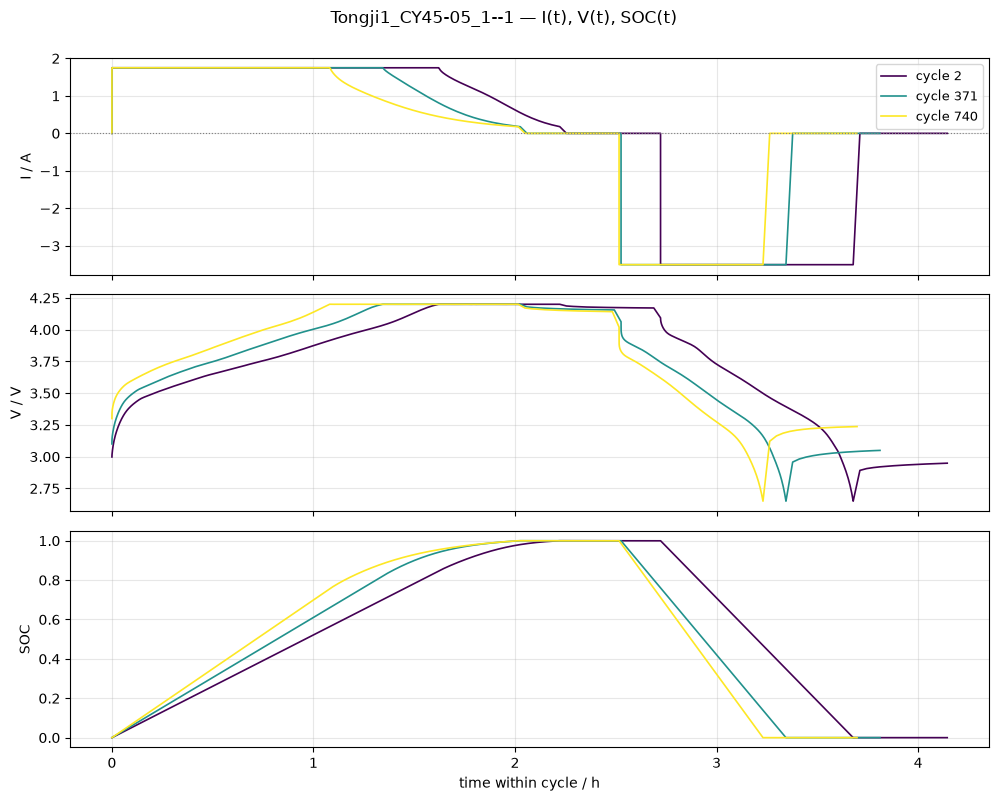

In [4]:
"""可视化 I(t) / V(t) / SOC(t)：叠加 SHOW_CYCLES 指定的代表循环。"""
import matplotlib.pyplot as plt
import numpy as np


def cycle_arrays(cyc):
    """把一圈数据整理成时间（相对该圈起点，单位 h）与各通道数组。"""
    t = np.asarray(cyc["time_in_s"], dtype=float)
    return dict(
        t_h=(t - t[0]) / 3600.0,
        I=np.asarray(cyc["current_in_A"], dtype=float),
        V=np.asarray(cyc["voltage_in_V"], dtype=float),
        qc=np.asarray(cyc["charge_capacity_in_Ah"], dtype=float),
        qd=np.asarray(cyc["discharge_capacity_in_Ah"], dtype=float),
    )


def build_soc(arr):
    """分段重建 SOC：充电段 qc/qc_max，充后静置=1，放电段 1-qd/qd_max，放后静置=0。"""
    I, qc, qd = arr["I"], arr["qc"], arr["qd"]
    soc = np.zeros_like(I)

    chg = np.where(I > I_TH)[0]
    dis = np.where(I < -I_TH)[0]
    if len(chg) == 0 or len(dis) == 0:
        raise ValueError(f"未找到完整的充电/放电段（I_TH={I_TH:.4f} A）")

    qc_max, qd_max = qc.max(), qd.max()
    soc[chg[0] : chg[-1] + 1] = qc[chg[0] : chg[-1] + 1] / qc_max
    soc[chg[-1] + 1 : dis[0]] = 1.0  # 充后静置
    soc[dis[0] : dis[-1] + 1] = 1.0 - qd[dis[0] : dis[-1] + 1] / qd_max
    soc[dis[-1] + 1 :] = 0.0  # 放后静置
    return np.clip(soc, 0.0, 1.0), qc_max, qd_max


fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
cmap = plt.get_cmap("viridis")

for k, cycle_number in enumerate(SHOW_CYCLES):
    cyc = next(c for c in cycles if c["cycle_number"] == cycle_number)
    arr = cycle_arrays(cyc)
    soc, qc_max, qd_max = build_soc(arr)
    color = cmap(k / max(len(SHOW_CYCLES) - 1, 1))

    axes[0].plot(
        arr["t_h"], arr["I"], color=color, lw=1.2, label=f"cycle {cycle_number}"
    )
    axes[1].plot(arr["t_h"], arr["V"], color=color, lw=1.2)
    axes[2].plot(arr["t_h"], soc, color=color, lw=1.2)

    print(
        f"cycle {cycle_number:>4d}: 充电容量 {qc_max:.3f} Ah | "
        f"放电容量 {qd_max:.3f} Ah | SOH {qd_max / NOMINAL:.1%} | "
        f"时长 {arr['t_h'][-1]:.2f} h"
    )

axes[0].set_ylabel("I / A")
axes[0].axhline(0, color="grey", lw=0.8, ls=":")
axes[1].set_ylabel("V / V")
axes[2].set_ylabel("SOC")
axes[2].set_xlabel("time within cycle / h")
axes[2].set_ylim(-0.05, 1.05)
axes[0].legend(loc="upper right", fontsize=9)

for ax in axes:
    ax.grid(alpha=0.3)

fig.suptitle(f"{cell['cell_id']} — I(t), V(t), SOC(t)", y=0.995)
fig.tight_layout()
plt.show()


首次 SOH<=80% 的圈号: 449
圈数: 711 | 放电容量: 2.500 → 3.347 Ah | SOH: 71.4% → 95.6%


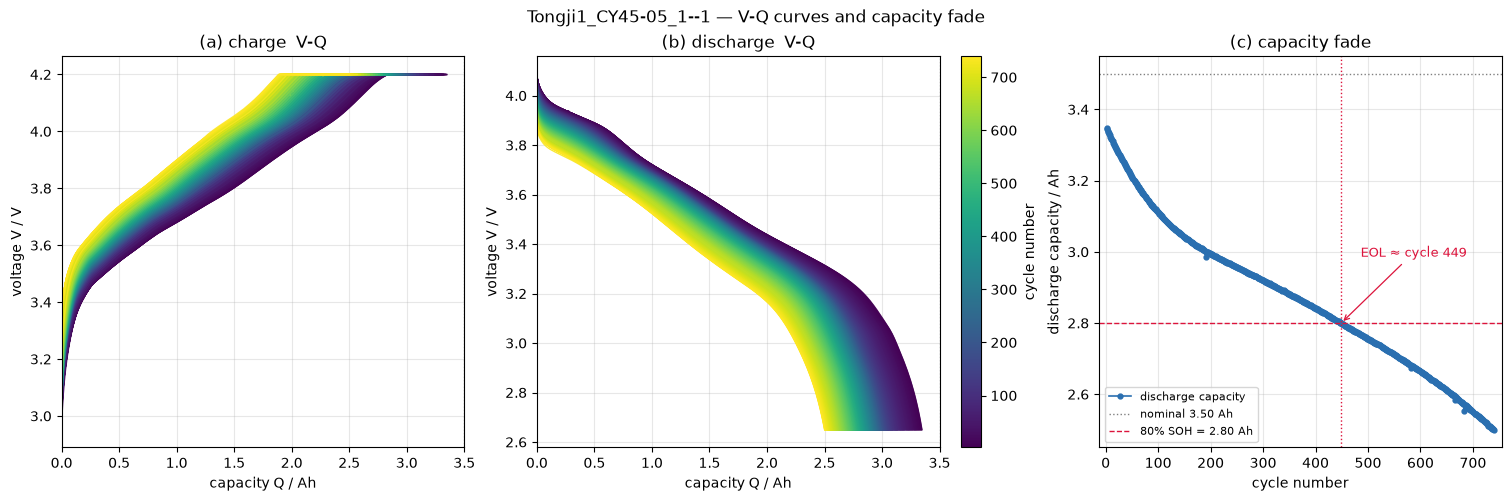

In [5]:
"""V-Q 曲线（按圈染色）与放电容量-圈数衰减曲线。"""
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("viridis")
# 只有 1 圈时 vmin==vmax，Norm 会退化，这里兜底
vmin, vmax = min(numbers), max(numbers)
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax if vmax > vmin else vmin + 1)

# 每圈放电容量：容量通道在静置段保留末值，所以取最大值
q_dis = np.array([max(c["discharge_capacity_in_Ah"]) for c in cycles], dtype=float)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.9), layout="constrained")

# ---------- (a) 充电 V-Q ----------
# ---------- (b) 放电 V-Q ----------
for c in cycles:
    color = cmap(norm(c["cycle_number"]))
    qc = np.asarray(c["charge_capacity_in_Ah"], dtype=float)
    qd = np.asarray(c["discharge_capacity_in_Ah"], dtype=float)
    I = np.asarray(c["current_in_A"], dtype=float)
    V = np.asarray(c["voltage_in_V"], dtype=float)

    # 用电流符号切阶段（容量通道在静置段残留末值，直接用 >0 会混入静置竖线）
    chg = I > I_TH
    dis = I < -I_TH
    axes[0].plot(qc[chg], V[chg], color=color, lw=1.0, alpha=0.9)
    axes[1].plot(qd[dis], V[dis], color=color, lw=1.0, alpha=0.9)

axes[0].set_title("(a) charge  V-Q")
axes[1].set_title("(b) discharge  V-Q")
for ax in axes[:2]:
    ax.set_xlabel("capacity Q / Ah")
    ax.set_ylabel("voltage V / V")
    ax.grid(alpha=0.3)
    ax.set_xlim(0, NOMINAL)
    ax.axvline(NOMINAL, color="grey", ls=":", lw=0.9)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=axes[:2], pad=0.012, fraction=0.03)
cb.set_label("cycle number")

# ---------- (c) 放电容量衰减 ----------
eol_q = EOL_SOH * NOMINAL
axes[2].plot(
    numbers,
    q_dis,
    marker="o",
    ms=3.5,
    lw=1.2,
    color="#2a6fb0",
    label="discharge capacity",
)
axes[2].axhline(
    NOMINAL, color="grey", ls=":", lw=1.0, label=f"nominal {NOMINAL:.2f} Ah"
)
axes[2].axhline(
    eol_q, color="crimson", ls="--", lw=1.0, label=f"{EOL_SOH:.0%} SOH = {eol_q:.2f} Ah"
)

below = np.array(numbers)[q_dis <= eol_q]
if len(below):
    eol = below[0]
    span_x = max(numbers) - min(numbers)
    span_y = np.nanmax(q_dis) - np.nanmin(q_dis)
    axes[2].axvline(eol, color="crimson", ls=":", lw=1.0)
    axes[2].annotate(
        f"EOL ≈ cycle {eol}",
        xy=(eol, eol_q),
        xytext=(eol + 0.05 * span_x, eol_q + 0.22 * span_y),
        arrowprops=dict(arrowstyle="->", color="crimson", lw=0.9),
        fontsize=9,
        color="crimson",
    )
    print(f"首次 SOH<={EOL_SOH:.0%} 的圈号: {eol}")
else:
    print(f"该电芯在记录范围内未跌到 {EOL_SOH:.0%} SOH")

axes[2].set_title("(c) capacity fade")
axes[2].set_xlabel("cycle number")
axes[2].set_ylabel("discharge capacity / Ah")
axes[2].set_xlim(
    min(numbers) - 0.02 * max(span_x, 1), max(numbers) + 0.02 * max(span_x, 1)
)
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8, loc="lower left")

print(
    f"圈数: {len(cycles)} | 放电容量: {np.nanmin(q_dis):.3f} → {np.nanmax(q_dis):.3f} Ah | "
    f"SOH: {np.nanmin(q_dis) / NOMINAL:.1%} → {np.nanmax(q_dis) / NOMINAL:.1%}"
)

fig.suptitle(f"{cell['cell_id']} — V-Q curves and capacity fade")
plt.show()


IC 曲线: 711 圈 | 峰高上限 P99 = 4.95 Ah/V | bins=300, win=15, CC>=50%


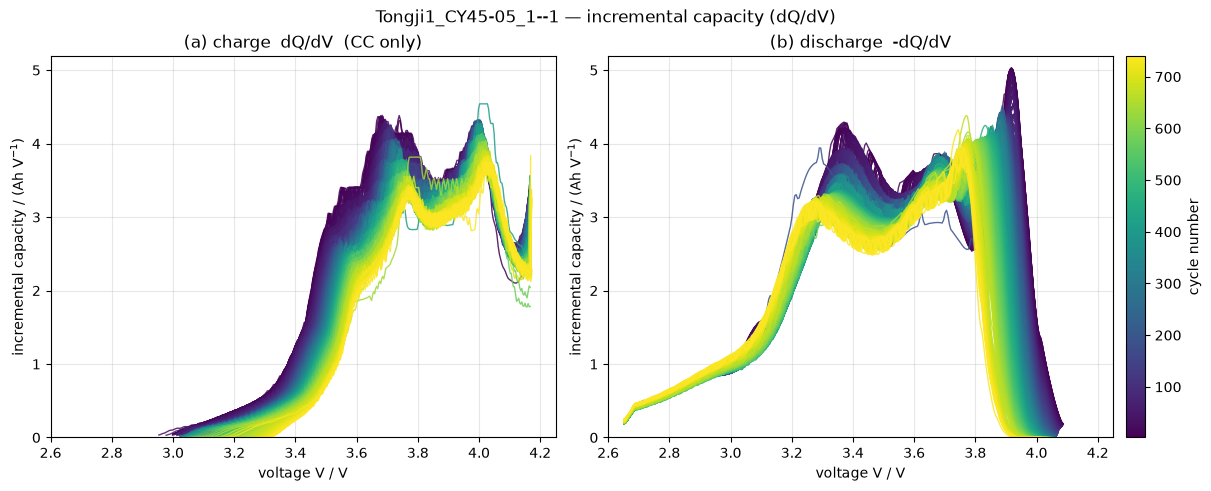

In [ ]:
"""IC 曲线（dQ/dV）：充电与放电各一幅，按圈染色。

处理要点
--------
1. 原始数据按时间采样，直接对相邻点做差分会被 1 s 的电压噪声放大，
   因此先把曲线按电压分箱、箱内取容量均值，再在均匀电压网格上平滑求导。
2. 充电的恒压（CV）段 dV≈0 而 dQ 很大，会把 dQ/dV 拉到几十上百并压扁整张图，
   所以充电只取 CC 段（电流 > 该段最大电流的 IC_CC_FRACTION 倍）。
3. 平滑不能直接对空数组 use mode="same"（边界补零会在两端制造巨大尖峰），
   这里用 edge padding。
"""
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

IC_BINS = 300  # 电压分箱数
IC_WIN = 15  # 平滑窗口（bin 数），越大越平滑
IC_CC_FRACTION = 0.5  # 充电只保留电流大于该比例的 CC 段，避开 CV 平台
IC_TRIM_FRAC = 0.03  # 充电曲线裁掉顶端该比例的电压跨度（CC→CV 交界处 dV→0，dQ/dV 发散）
IC_P99 = 99.0  # y 轴上限取该分位数


def ic_curve(V, Q, bins=IC_BINS, win=IC_WIN):
    """分箱均值 + 平滑求导，返回 (电压, dQ/dV)。"""
    V = np.asarray(V, dtype=float)
    Q = np.asarray(Q, dtype=float)
    if V.size < bins // 2:
        return np.array([]), np.array([])

    order = np.argsort(V)
    V, Q = V[order], Q[order]

    edges = np.linspace(V.min(), V.max(), bins + 1)
    idx = np.clip(np.digitize(V, edges) - 1, 0, bins - 1)
    cnt = np.bincount(idx, minlength=bins)
    sum_q = np.bincount(idx, weights=Q, minlength=bins)
    ok = cnt > 0
    if ok.sum() < 5:
        return np.array([]), np.array([])

    v_centers = 0.5 * (edges[:-1] + edges[1:])[ok]
    q_mean = sum_q[ok] / cnt[ok]

    grid = np.linspace(v_centers[0], v_centers[-1], bins)
    q_grid = np.interp(grid, v_centers, q_mean)

    win = max(3, int(win) | 1)  # 保证奇数
    m = win // 2
    q_smooth = np.convolve(
        np.pad(q_grid, m, mode="edge"), np.ones(win) / win, mode="valid"
    )
    return grid, np.gradient(q_smooth, grid)


cmap = plt.get_cmap("viridis")
vmin, vmax = min(numbers), max(numbers)
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax if vmax > vmin else vmin + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
ic_peak = 0.0

for c in cycles:
    color = cmap(norm(c["cycle_number"]))
    V = np.asarray(c["voltage_in_V"], dtype=float)
    I = np.asarray(c["current_in_A"], dtype=float)
    qc = np.asarray(c["charge_capacity_in_Ah"], dtype=float)
    qd = np.asarray(c["discharge_capacity_in_Ah"], dtype=float)

    i_cc = IC_CC_FRACTION * I[I > 0].max() if (I > 0).any() else I_TH
    v_c, ic_c = ic_curve(V[I > max(i_cc, I_TH)], qc[I > max(i_cc, I_TH)])
    v_d, ic_d = ic_curve(V[I < -I_TH], qd[I < -I_TH])

    if v_c.size:  # CC→CV 交界 dQ/dV 发散，裁掉顶端一小段
        keep = v_c <= v_c.max() - IC_TRIM_FRAC * (v_c.max() - v_c.min())
        v_c, ic_c = v_c[keep], ic_c[keep]

    axes[0].plot(v_c, ic_c, color=color, lw=1.0, alpha=0.85)
    axes[1].plot(
        v_d, -ic_d, color=color, lw=1.0, alpha=0.85
    )  # 放电 dQ/dV<0，取负号画正峰

    for y in (ic_c, -ic_d):
        if y.size:
            ic_peak = max(ic_peak, np.nanpercentile(y, IC_P99))

axes[0].set_title("(a) charge  dQ/dV  (CC only)")
axes[1].set_title("(b) discharge  -dQ/dV")
for ax in axes:
    ax.set_xlabel("voltage V / V")
    ax.set_ylabel("incremental capacity / (Ah V$^{-1}$)")
    ax.grid(alpha=0.3)
    ax.set_xlim(
        cell["min_voltage_limit_in_V"] - 0.05, cell["max_voltage_limit_in_V"] + 0.05
    )
    ax.set_ylim(0, ic_peak * 1.05)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=axes, pad=0.012, fraction=0.03)
cb.set_label("cycle number")

print(
    f"IC 曲线: {len(cycles)} 圈 | 峰高上限 P{IC_P99:.0f} = {ic_peak:.2f} Ah/V | "
    f"bins={IC_BINS}, win={IC_WIN}, CC>={IC_CC_FRACTION:.0%}"
)

fig.suptitle(f"{cell['cell_id']} — incremental capacity (dQ/dV)")
plt.show()
